# Asignación 3 — Model Selection y Optimización de Hiperparámetros

**Proyecto:** Super Smash Bros. Melee Victory Predictor  
**Fuente:** `notebooks/01_eda.ipynb` y `notebooks/02_data_preparation.ipynb`

## Sección 0 — Preparación del entorno de trabajo

Esta sección deja el notebook listo para modelar sin depender del estado del kernel del notebook 02.

**Reglas de la asignación que se respetan desde aquí:**

- El conjunto de `test` no participa en selección de features, modelos ni hiperparámetros.
- El preprocesado se ajusta dentro de cada fold; por eso se guarda como pipeline **sin fit**.
- No se usan `X_train_proc` ni `X_test_proc` del notebook 02 para la validación cruzada: esos arrays se ajustaron sobre todo `X_train` y filtrarían estadísticas de los folds de validación.
- El split y los grupos se reconstruyen de forma determinista desde el parquet, con la misma lógica del notebook 02.

### Contrato de datos

| Variable | Tipo | Contenido |
|---|---|---|
| `X_train` | DataFrame | 426 378 × 46, sin `outcome` |
| `X_test` | DataFrame | 108 610 × 46, sin `outcome` |
| `y_train` | Series | 426 378, `outcome` ∈ {1, 2} |
| `y_test` | Series | 108 610, `outcome` ∈ {1, 2} |
| `groups_train_raw` | ndarray | 39 grupos, orden posicional de `X_train` |
| `groups_train_cv` | ndarray | 38 grupos, con `0000_m25 → 0000_m16` |
| `groups_test` | ndarray | 10 grupos |
| `full_pipeline_sin_fit` | Pipeline | `MeleeFeatureEngineer` + `ColumnTransformer`, sin `.fit()` |

**Ejecutar desde `notebooks/`**, porque el dataset se resuelve con `../data/processed_sample.parquet`.

In [1]:
from __future__ import annotations

import time
from pathlib import Path
from typing import Optional, Sequence

import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.utils import Tags, TransformerTags

assert tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 6), (
    f"Se requiere scikit-learn >= 1.6; instalado: {sklearn.__version__}"
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "outcome"
ID_GROUP = "match_id"
ID_FRAME = "row_id"

DATA_PATH = Path("../data/processed_sample.parquet")
assert DATA_PATH.exists(), f"No se encontró el dataset: {DATA_PATH}"

print(f"scikit-learn: {sklearn.__version__}")
print(f"Dataset     : {DATA_PATH}")

scikit-learn: 1.9.1
Dataset     : ../data/processed_sample.parquet


In [2]:
df = pd.read_parquet(DATA_PATH)

# Misma depuración que notebook 02 §5
df = df.loc[
    ~((df["frame"] < 0) | (df["p1_stock"] == 0) | (df["p2_stock"] == 0))
].reset_index(drop=True)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)
train_idx, test_idx = next(
    splitter.split(df, df[TARGET], groups=df[ID_GROUP])
)

X_train = df.iloc[train_idx].drop(columns=[TARGET])
X_test = df.iloc[test_idx].drop(columns=[TARGET])
y_train = df[TARGET].iloc[train_idx]
y_test = df[TARGET].iloc[test_idx]

groups_train_raw = df[ID_GROUP].iloc[train_idx].to_numpy()
groups_train_cv = np.where(
    groups_train_raw == "0000_m25", "0000_m16", groups_train_raw
)
groups_test = df[ID_GROUP].iloc[test_idx].to_numpy()

print(f"Dataset depurado : {df.shape}")
print(f"X_train          : {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test           : {X_test.shape} | y_test : {y_test.shape}")
print(f"Partidas train   : {pd.Series(groups_train_raw).nunique()} raw | "
      f"{pd.Series(groups_train_cv).nunique()} CV")
print(f"Partidas test    : {pd.Series(groups_test).nunique()}")

Dataset depurado : (534988, 47)
X_train          : (426378, 46) | y_train: (426378,)
X_test           : (108610, 46) | y_test : (108610,)
Partidas train   : 39 raw | 38 CV
Partidas test    : 10


In [3]:
# --- Clase MeleeFeatureEngineer (definición autocontenida) -----------------
# Clase definida aquí para que el notebook sea autocontenido.

__all__ = [
    "EPSILON",
    "DERIVED_FEATURES",
    "REQUIRED_COLUMNS",
    "MeleeFeatureEngineer",
]

#: Constante de estabilización para divisiones por cero en ratios de stock.
EPSILON: float = 1e-5

#: Variables derivadas, en el orden estable en que se anexan al DataFrame.
DERIVED_FEATURES: tuple[str, ...] = (
    "stock_diff",
    "percent_diff",
    "stock_ratio",
    "spatial_distance",
    "p1_edgeguard_advantage",
)

#: Columnas que el transformer necesita encontrar en el DataFrame de entrada.
REQUIRED_COLUMNS: tuple[str, ...] = (
    "p1_stock",
    "p2_stock",
    "p1_percent",
    "p2_percent",
    "p1_x",
    "p2_x",
    "p1_y",
    "p2_y",
    "p1_off_stage",
    "p2_off_stage",
)


class MeleeFeatureEngineer(BaseEstimator, TransformerMixin):
    """Agrega variables de dominio de SSBM a un DataFrame de frames.

    El transformador se sitúa **al inicio** de un ``Pipeline`` de Scikit-Learn:
    primero calcula las variables derivadas y después un ``ColumnTransformer``
    aplica imputación y escalado únicamente a las columnas que interesen.

    El estado de la partida se modela como fotograma a fotograma (1/60 s). Cada
    fila de entrada contiene el estado completo de los dos jugadores en un
    instante concreto, por lo que todas las variables derivadas son
    deterministas y sin dependencias temporales: no requieren información de
    frames vecinos ni del resultado final de la partida.

    Notes
    -----
    La entrada **nunca se modifica**: ``fit`` y ``transform`` trabajan sobre una
    copia y anexan las columnas nuevas a esa copia.

    ``stock_ratio`` usa :data:`EPSILON` en el denominador para evitar divisiones
    por cero. Sobre los datos ya depurados, donde ``p2_stock >= 1`` en todas las
    filas, el denominador nunca se aproxima a cero y la variable queda acotada en
    [0,2500 ; 4,0000], con máximo 3,99996. El caso extremo aparece solo si este
    transformador se aplica a datos sin depurar: ``p2_stock`` llega a 0 en 26 de
    las 540 940 filas crudas y ahí la variable alcanza 400 000, lo que tras
    ``StandardScaler`` comprimiría el rango del resto de las filas hacia cero.
    """

    def __init__(self, epsilon: float = EPSILON) -> None:
        """Inicializa el transformador.

        Parameters
        ----------
        epsilon : float, default=EPSILON
            Constante de estabilización añadida al denominador de los ratios
            para evitar divisiones por cero. Debe ser estrictamente positiva.

        Notes
        -----
        Scikit-Learn exige que ``__init__`` declare todos los parámetros como
        argumentos con nombre y los guarde en atributos homónimos, para que
        ``get_params`` y ``clone`` funcionen dentro de un ``Pipeline``.
        """
        self.epsilon = epsilon

    # ------------------------------------------------------------------
    # API de Scikit-Learn
    # ------------------------------------------------------------------

    def __sklearn_tags__(self) -> Tags:
        """Declara el rol de transformer para la introspección de Scikit-Learn.

        Returns
        -------
        Tags
            Etiquetas con ``estimator_type='transformer'`` y sin requirement de
            ``y``. ``preserves_dtype`` se deja vacío porque el transformador
            cambia la forma del DataFrame: no preserva ni el dtype ni el número
            de columnas.
        """
        tags = super().__sklearn_tags__()
        tags.estimator_type = "transformer"
        tags.transformer_tags = TransformerTags(preserves_dtype=[])
        tags.target_tags.required = False
        return tags

    def fit(self, X: pd.DataFrame, y: object = None) -> "MeleeFeatureEngineer":
        """Valida la entrada y memoriza sus columnas.

        Parameters
        ----------
        X : pandas.DataFrame
            Estado de la partida con al menos las columnas de
            :data:`REQUIRED_COLUMNS`. No se modifica.
        y : object, default=None
            Vector objetivo. Se acepta por compatibilidad con la API de
            Scikit-Learn y se ignora: este transformador es no supervisado.

        Returns
        -------
        MeleeFeatureEngineer
            El propio instancia, ya ajustada.

        Raises
        ------
        TypeError
            Si ``X`` no es un ``pandas.DataFrame``.
        ValueError
            Si falta alguna columna de :data:`REQUIRED_COLUMNS`.

        Notes
        -----
        El cálculo de todas las variables derivadas es determinista, por lo que
        ``fit`` no aprende ningún parámetro y ``transform`` puede aplicarse sin
        estado previo más allá del nombre de las columnas de entrada.
        """
        frame = self._copy_and_validate(X)
        self._fitted_feature_names = list(frame.columns)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        """Calcula y anexa las variables de dominio de SSBM.

        Parameters
        ----------
        X : pandas.DataFrame
            Estado de la partida con al menos las columnas de
            :data:`REQUIRED_COLUMNS`. No se modifica.

        Returns
        -------
        pandas.DataFrame
            Copia de ``X`` con las columnas de :data:`DERIVED_FEATURES` anexadas
            al final, en ese orden.

        Raises
        ------
        TypeError
            Si ``X`` no es un ``pandas.DataFrame``.
        ValueError
            Si falta alguna columna de :data:`REQUIRED_COLUMNS`.

        Notes
        -----
        ``p1_off_stage`` y ``p2_off_stage`` llegan como ``bool`` en este dataset,
        de modo que la comparación contra ``1`` / ``0`` es intencional y equivale
        a un operador ``~`` sobre el booleano.
        """
        frame = self._copy_and_validate(X)

        # Familia: diferencias y ratios de dominio.
        frame["stock_diff"] = frame["p1_stock"] - frame["p2_stock"]
        frame["percent_diff"] = frame["p2_percent"] - frame["p1_percent"]
        frame["stock_ratio"] = frame["p1_stock"] / (
            frame["p2_stock"] + self.epsilon
        )

        # Familia: reglas tácticas y distancia espacial.
        delta_x = frame["p1_x"] - frame["p2_x"]
        delta_y = frame["p1_y"] - frame["p2_y"]
        frame["spatial_distance"] = np.sqrt(delta_x**2 + delta_y**2)
        frame["p1_edgeguard_advantage"] = (
            (frame["p2_off_stage"] == 1) & (frame["p1_off_stage"] == 0)
        ).astype(np.int8)

        return frame

    def get_feature_names_out(
        self, input_features: Optional[Sequence[str]] = None
    ) -> np.ndarray:
        """Devuelve los nombres de las columnas producidas por ``transform``.

        Parameters
        ----------
        input_features : sequence of str, optional
            Nombres de las columnas de entrada. Si se omite, se usan las
            memorizadas durante ``fit``.

        Returns
        -------
        numpy.ndarray
            Nombres de salida: las columnas de entrada seguidas de
            :data:`DERIVED_FEATURES`.

        Raises
        ------
        ValueError
            Si no se recibe ``input_features`` y el transformador no ha sido
            ajustado, o si las columnas de entrada no cubren
            :data:`REQUIRED_COLUMNS`.

        Notes
        -----
        Permite que ``Pipeline.get_feature_names_out()`` enumere el espacio de
        características completo, que es lo que se inspecciona en la sección de
        verificaciones estructurales del notebook de preparación de datos.
        """
        if input_features is None:
            if self._fitted_feature_names is None:
                raise ValueError(
                    "No se pueden obtener los nombres de salida: hay que "
                    "llamar a fit antes, o pasar input_features explícitamente."
                )
            base = list(self._fitted_feature_names)
        else:
            base = list(input_features)

        missing = [c for c in REQUIRED_COLUMNS if c not in base]
        if missing:
            raise ValueError(
                f"Faltan columnas requeridas en input_features: {missing}"
            )

        return np.asarray(base + list(DERIVED_FEATURES), dtype=object)

    # ------------------------------------------------------------------
    # Utilidades internas
    # ------------------------------------------------------------------

    def _copy_and_validate(self, X: pd.DataFrame) -> pd.DataFrame:
        """Valida el tipo y las columnas requeridas, y devuelve una copia.

        Parameters
        ----------
        X : pandas.DataFrame
            Entrada a validar.

        Returns
        -------
        pandas.DataFrame
            Copia de ``X``, segura de modificar.

        Raises
        ------
        TypeError
            Si ``X`` no es un ``pandas.DataFrame``.
        ValueError
            Si falta alguna columna de :data:`REQUIRED_COLUMNS`.
        """
        if not isinstance(X, pd.DataFrame):
            raise TypeError(
                f"MeleeFeatureEngineer espera un pandas.DataFrame, "
                f"recibió {type(X).__name__}."
            )

        missing = [column for column in REQUIRED_COLUMNS if column not in X.columns]
        if missing:
            raise ValueError(
                f"Faltan columnas requeridas en la entrada: {missing}. "
                f"Columnas presentes: {list(X.columns)}"
            )

        return X.copy()

    # ``_fitted_feature_names`` se declara a nivel de clase para que
    # ``get_feature_names_out`` tenga un valor por defecto con el que fallar de
    # forma explícita antes del primer ``fit``.
    _fitted_feature_names: Optional[list[str]] = None

In [4]:
# --- Listas explícitas de variables ---------------------------------------
# Cada variable entra en exactamente una lista. Lo que no aparece en ninguna se
# descarta vía remainder='drop' y queda documentado abajo.
NUMERICAL_COLS = [
    # Progreso temporal de la partida
    "frame",
    # Stocks y daño acumulado
    "p1_stock", "p2_stock", "p1_percent", "p2_percent",
    # Escudo
    "p1_shield_strength", "p2_shield_strength",
    # Fotograma de la acción en curso
    "p1_action_frame", "p2_action_frame",
    # Frames de invulnerabilidad, hitlag, hitstun y saltos restantes
    "p1_invulnerability_left", "p2_invulnerability_left",
    "p1_hitlag_left", "p2_hitlag_left",
    "p1_hitstun_frames_left", "p2_hitstun_frames_left",
    "p1_jumps_left", "p2_jumps_left",
    # Coordenadas
    "p1_x", "p1_y", "p2_x", "p2_y",
    # Velocidades
    "p1_speed_air_x_self", "p1_speed_y_self", "p1_speed_ground_x_self",
    "p2_speed_air_x_self", "p2_speed_y_self", "p2_speed_ground_x_self",
    # Derivadas del dominio (sección 7)
    "stock_diff", "percent_diff", "stock_ratio", "spatial_distance",
]

CATEGORICAL_COLS = [
    "stage", "p1_character", "p2_character",
]

BINARY_COLS = [
    "p1_is_powershield", "p2_is_powershield",
    "p1_facing", "p2_facing",
    "p1_invulnerable", "p2_invulnerable",
    "p1_on_ground", "p2_on_ground",
    "p1_off_stage", "p2_off_stage",
    "p1_edgeguard_advantage",
]

EXCLUDE_COLS = [ID_FRAME, ID_GROUP, TARGET]

# --- Variables deliberadamente descartadas (remainder='drop') -------------
UNASSIGNED_COLS = [
    "p1_costume", "p2_costume", "p1_action", "p2_action",
]

print(f"NUMERICAL_COLS  : {len(NUMERICAL_COLS)}")
print(f"CATEGORICAL_COLS: {len(CATEGORICAL_COLS)}")
print(f"BINARY_COLS     : {len(BINARY_COLS)}")
print(f"EXCLUDE_COLS    : {EXCLUDE_COLS}")

# --- Comprobación: cada columna original cae en una categoría válida --------
asignadas = set(NUMERICAL_COLS) | set(CATEGORICAL_COLS) | set(BINARY_COLS)
disponibles = set(df.columns) | set(DERIVED_FEATURES)
originales = [c for c in df.columns if c not in EXCLUDE_COLS]
sin_asignar = sorted(c for c in originales if c not in asignadas)
faltantes = sorted(c for c in asignadas if c not in disponibles)

print(f"\nColumnas originales fuera de EXCLUDE_COLS : {len(originales)}")
print(f"Asignadas a alguna lista                  : {len(originales) - len(sin_asignar)}")
print(f"Descartadas por remainder='drop'          : {sin_asignar}")
print(f"Declaradas pero ausentes del dataset      : {faltantes or 'ninguna'}")
assert sin_asignar == sorted(UNASSIGNED_COLS), f"Descartadas inesperadas: {sin_asignar}"
assert not faltantes, f"Columnas declaradas que no existen: {faltantes}"
print("\nCobertura de columnas verificada.")

NUMERICAL_COLS  : 31
CATEGORICAL_COLS: 3
BINARY_COLS     : 11
EXCLUDE_COLS    : ['row_id', 'match_id', 'outcome']

Columnas originales fuera de EXCLUDE_COLS : 44
Asignadas a alguna lista                  : 40
Descartadas por remainder='drop'          : ['p1_action', 'p1_costume', 'p2_action', 'p2_costume']
Declaradas pero ausentes del dataset      : ninguna

Cobertura de columnas verificada.


In [5]:
# --- Sub-pipelines por tipo de variable ------------------------------------
numeric_pipeline = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalado", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="constant", fill_value="missing")),
        ("codificacion", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)


def as_float_matrix(frame: pd.DataFrame) -> np.ndarray:
    """Convierte un sub-DataFrame binario en una matriz float32."""
    return frame.astype(np.float32).to_numpy()


binary_pipeline = Pipeline(
    steps=[
        ("casteo", FunctionTransformer(as_float_matrix, feature_names_out="one-to-one")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, NUMERICAL_COLS),
        ("cat", categorical_pipeline, CATEGORICAL_COLS),
        ("bin", binary_pipeline, BINARY_COLS),
    ],
    remainder="drop",
)

# Pipeline completo SIN ajustar. Cada fold lo clonará y ajustará.
full_pipeline_sin_fit = Pipeline(
    steps=[
        ("features", MeleeFeatureEngineer(epsilon=EPSILON)),
        ("preprocess", preprocessor),
    ]
)

print("Pipeline completo (sin fit):")
print(full_pipeline_sin_fit)
print(f"\nPasos: {[nombre for nombre, _ in full_pipeline_sin_fit.steps]}")

Pipeline completo (sin fit):
Pipeline(steps=[('features', MeleeFeatureEngineer()),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalado',
                                                                   StandardScaler())]),
                                                  ['frame', 'p1_stock',
                                                   'p2_stock', 'p1_percent',
                                                   'p2_percent',
                                                   'p1_shield_strength',
                                                   'p2_shield_strength',
                                                   'p1_action_frame',
                                                 

In [6]:
# --- Validaciones de cierre de la Sección 0 --------------------------------
assert df.shape == (534_988, 47)
assert X_train.shape == (426_378, 46)
assert X_test.shape == (108_610, 46)
assert y_train.shape == (426_378,)
assert y_test.shape == (108_610,)

assert (X_train.index == y_train.index).all()
assert np.array_equal(groups_train_raw, X_train[ID_GROUP].to_numpy())
assert len(groups_train_cv) == len(X_train) == len(y_train)
assert pd.Series(groups_train_raw).nunique() == 39
assert pd.Series(groups_train_cv).nunique() == 38
assert pd.Series(groups_test).nunique() == 10
assert set(groups_train_cv).isdisjoint(set(groups_test))
assert "0000_m16" in set(groups_train_cv)
assert "0000_m25" not in set(groups_train_cv)

assert sorted(y_train.unique().tolist()) == [1, 2]
assert sorted(y_test.unique().tolist()) == [1, 2]

assert full_pipeline_sin_fit.named_steps["features"]._fitted_feature_names is None
assert not hasattr(full_pipeline_sin_fit.named_steps["preprocess"], "transformers_")

print("Balance y_train:")
print(y_train.value_counts(normalize=True).sort_index().round(6).to_string())
print("\nSección 0 verificada: datos crudos, split agrupado y pipeline sin fit.")
print("[OK] X_train/X_test crudos, sin X_train_proc ni X_test_proc")
print("[OK] groups_train_raw=39, groups_train_cv=38, groups_test=10")
print("[OK] indices X_train/y_train alineados")
print("[OK] full_pipeline_sin_fit sin .fit()")
print("[OK] test reservado para la evaluación final")

Balance y_train:
outcome
1    0.552847
2    0.447153

Sección 0 verificada: datos crudos, split agrupado y pipeline sin fit.
[OK] X_train/X_test crudos, sin X_train_proc ni X_test_proc
[OK] groups_train_raw=39, groups_train_cv=38, groups_test=10
[OK] indices X_train/y_train alineados
[OK] full_pipeline_sin_fit sin .fit()
[OK] test reservado para la evaluación final


### Checklist de aceptación — Sección 0

- [x] El notebook corre desde `notebooks/` con kernel reiniciado.
- [x] `DATA_PATH` existe y apunta a `../data/processed_sample.parquet`.
- [x] El filtrado es exactamente `frame < 0` y `stock == 0`.
- [x] El split es `GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)` agrupado por `match_id`.
- [x] Se obtienen 39 partidas en train y 10 en test, sin solapamiento.
- [x] `X_train.index` y `y_train.index` coinciden exactamente.
- [x] `groups_train_raw` respeta el orden posicional de `X_train`.
- [x] `groups_train_cv` tiene 38 grupos y `0000_m25` ya no aparece.
- [x] `groups_test` conserva sus 10 grupos originales.
- [x] La clase `MeleeFeatureEngineer` y las listas son las del notebook 02, no las de `src/`.
- [x] `full_pipeline_sin_fit` está sin ajustar.
- [x] No se creó `X_train_proc` ni `X_test_proc`.
- [x] No se evaluó ningún modelo ni se tocó `test`.

**Fin de la Sección 0.** La Sección 1 (objetivo, métrica y protocolo) se añadirá después de cerrar el diagnóstico del pipeline.

## Sección 1 — Objetivo, métrica y protocolo de evaluación

### Objetivo

Predecir, a partir del estado de un frame 1v1, si gana el jugador 1 (`outcome = 1`) o el jugador 2 (`outcome = 2`). Es un problema de **clasificación binaria supervisada**. El objetivo no es solo maximizar una métrica: es seleccionar un pipeline que **generalice a partidas no vistas**. Por eso el conjunto de `test` (10 partidas) queda reservado para una única evaluación final y no participa en la selección.

### Métricas

**Métrica principal: accuracy.**
- Es la métrica comparable con el baseline de dominio (75.03%) y con el `DummyClassifier`.
- Representa la proporción de frames cuyo ganador se predice correctamente.
- El error real que representa es la proporción de frames mal clasificados: `1 - accuracy`.
- Limitación: con clases cercanas a 55/45, accuracy puede favorecer a la clase mayoritaria y ocultar un mal desempeño sobre P2.

**Métrica principal complementaria: F1 macro.**
- Es el promedio no ponderado del F1 de P1 y del F1 de P2.
- Penaliza que el modelo abandone la clase minoritaria, algo que accuracy sola no detecta.
- Se reportará junto a accuracy; **no se seleccionará un modelo solo por accuracy** si su F1 macro es pobre.

**Métrica de apoyo: ROC AUC.**
- Resume la capacidad de ordenar frames por probabilidad de victoria de P1.
- Se reportará cuando el modelo exponga `predict_proba`; no sustituye a accuracy ni a F1 macro.

**Coste real del error.** En un uso de análisis en vivo o de apoyo a decisiones/apuestas, un falso positivo de P1 (predecir P1 cuando gana P2) y un falso negativo de P1 (predecir P2 cuando gana P1) no tienen el mismo coste: una predicción confiada en el lado equivocado puede inducir una decisión táctica o económica incorrecta. Como el proyecto no define una matriz de costes concreta, se usa accuracy como métrica principal, F1 macro para vigilar el balance entre P1 y P2, y ROC AUC como apoyo.

También se registrará el **tiempo de validación cruzada** como criterio de costo computacional.

### Protocolo de validación

Se usa `GroupKFold(n_splits=5)` agrupando por `match_id`, con `groups_train_cv` (38 grupos, tras unificar `0000_m25` con `0000_m16`).

**Por qué GroupKFold y no KFold/StratifiedKFold:**
- Cada fila es un frame; los frames de una misma partida están fuertemente autocorrelacionados y comparten el mismo `outcome`.
- Un `KFold` o `StratifiedKFold` normal repartiría frames de la misma partida entre train y validación. El modelo podría reconocer la partida y memorizar su resultado; la métrica de validación sería optimista.
- `GroupKFold` mantiene cada partida completa en un solo lado del split, de modo que la validación mide generalización a partidas nuevas.

**Por qué 5 folds:**
- Con 38 grupos, 5 folds dejan aproximadamente **7-8 partidas por fold de validación** (≈20% de las filas).
- Menos folds (por ejemplo, 3) darían menos estimaciones y una desviación más ruidosa.
- Más folds (por ejemplo, 10) dejarían muy pocas partidas por validación y aumentarían la varianza.
- 5 folds es un equilibrio razonable entre costo, número de estimaciones y tamaño del conjunto de validación.

**Reglas del protocolo:**
- El mismo objeto `cv` y el mismo `groups_train_cv` se usan para el Dummy y para los tres modelos candidatos.
- El preprocesado se ajusta **dentro de cada fold**, mediante un `Pipeline` que incluye features + preprocesado + clasificador. No se usan `X_train_proc` ni `X_test_proc` del notebook 02.
- No se toca `test` hasta la evaluación final.
- Una diferencia pequeña entre modelos no se considerará superioridad si queda dentro de la variación entre folds.

In [7]:
from sklearn.model_selection import GroupKFold

N_SPLITS = 5
cv = GroupKFold(n_splits=N_SPLITS)

print(f"GroupKFold: {N_SPLITS} folds | grupos únicos: {pd.Series(groups_train_cv).nunique()}")
print(f"X_train: {len(X_train):,} filas\n")

val_sizes = []
for fold, (tr, va) in enumerate(
    cv.split(X_train, y_train, groups=groups_train_cv), start=1
):
    grupos_tr = pd.Series(groups_train_cv[tr])
    grupos_va = pd.Series(groups_train_cv[va])

    assert set(grupos_tr).isdisjoint(set(grupos_va)), (
        f"El fold {fold} comparte partidas entre train y validación."
    )

    val_sizes.append(len(va))

    print(
        f"Fold {fold}: "
        f"train={len(tr):,} filas / {grupos_tr.nunique()} partidas | "
        f"valid={len(va):,} filas / {grupos_va.nunique()} partidas"
    )
    print(
        "  train clases:",
        y_train.iloc[tr].value_counts(normalize=True).sort_index().round(4).to_dict(),
    )
    print(
        "  valid clases:",
        y_train.iloc[va].value_counts(normalize=True).sort_index().round(4).to_dict(),
    )

assert sum(val_sizes) == len(X_train), (
    "Los folds de validación no cubren exactamente todas las filas de X_train."
)

print(f"\nCobertura de validación: {sum(val_sizes):,} = {len(X_train):,} filas de X_train")
print("Folds definidos una sola vez en `cv`; se reutilizarán para todos los modelos.")

GroupKFold: 5 folds | grupos únicos: 38
X_train: 426,378 filas



Fold 1: train=340,048 filas / 31 partidas | valid=86,330 filas / 7 partidas
  train clases: {1: 0.5916, 2: 0.4084}
  valid clases: {1: 0.4, 2: 0.6}


Fold 2: train=339,944 filas / 30 partidas | valid=86,434 filas / 8 partidas
  train clases: {1: 0.5418, 2: 0.4582}
  valid clases: {1: 0.5965, 2: 0.4035}


Fold 3: train=346,575 filas / 31 partidas | valid=79,803 filas / 7 partidas
  train clases: {1: 0.5479, 2: 0.4521}
  valid clases: {1: 0.5745, 2: 0.4255}


Fold 4: train=339,463 filas / 30 partidas | valid=86,915 filas / 8 partidas
  train clases: {1: 0.572, 2: 0.428}
  valid clases: {1: 0.4781, 2: 0.5219}


Fold 5: train=339,482 filas / 30 partidas | valid=86,896 filas / 8 partidas
  train clases: {1: 0.511, 2: 0.489}
  valid clases: {1: 0.7161, 2: 0.2839}

Cobertura de validación: 426,378 = 426,378 filas de X_train
Folds definidos una sola vez en `cv`; se reutilizarán para todos los modelos.


**Interpretación de los folds.** Los 5 folds dejan 7-8 partidas por validación (79 803-86 915 frames). El balance de clases varía bastante: el fold 1 tiene 40/60 en validación y el fold 5, 71.6/28.4. No es un error: refleja la variabilidad de tener solo 38 partidas y refuerza la necesidad de reportar F1 macro y desviación estándar, no solo accuracy.

## Sección 2 — Baseline trivial con `DummyClassifier`

### Motivación

Antes de comparar modelos reales necesitamos una **referencia ingenua**. `DummyClassifier(strategy="most_frequent")` predice siempre la clase mayoritaria de train y no aprende ninguna relación entre las features y el resultado.

Este baseline **no es el baseline de dominio del 75.03%**. Es el suelo trivial: sirve para comprobar el desbalance de clases y para fijar el mínimo que cualquier modelo real debe superar.

Como el Dummy ignora `X`, no necesita preprocesado: aplicar imputadores, escaladores u one-hot no cambiaría sus predicciones. Lo importante es evaluarlo con **el mismo `cv` y los mismos `groups_train_cv`** que usarán los modelos candidatos, para que la comparación sea pareada.

Se reportan accuracy, F1 macro y ROC AUC en media ± desviación estándar, más el tiempo de validación cruzada.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

SCORING = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc",
}

baseline = DummyClassifier(
    strategy="most_frequent",
    random_state=RANDOM_STATE,
)

t0 = time.perf_counter()
baseline_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    groups=groups_train_cv,
    cv=cv,
    scoring=SCORING,
    n_jobs=1,
    error_score="raise",
)
baseline_time = time.perf_counter() - t0

baseline_row = {
    "Modelo": "DummyClassifier",
    "Configuración": "strategy='most_frequent'",
    "Accuracy media": baseline_cv["test_accuracy"].mean(),
    "Accuracy std": baseline_cv["test_accuracy"].std(ddof=1),
    "F1 macro media": baseline_cv["test_f1_macro"].mean(),
    "F1 macro std": baseline_cv["test_f1_macro"].std(ddof=1),
    "ROC AUC media": baseline_cv["test_roc_auc"].mean(),
    "ROC AUC std": baseline_cv["test_roc_auc"].std(ddof=1),
    "Tiempo CV (s)": baseline_time,
}

tabla_baseline = pd.DataFrame([baseline_row]).set_index("Modelo")

print("Accuracy por fold:", np.round(baseline_cv["test_accuracy"], 6).tolist())
print("\nBaseline Dummy:")
print(tabla_baseline.round(6).to_string())

assert len(baseline_cv["test_accuracy"]) == cv.get_n_splits()
assert np.isclose(tabla_baseline.loc["DummyClassifier", "ROC AUC media"], 0.5)
assert 0.5 <= tabla_baseline.loc["DummyClassifier", "Accuracy media"] <= 0.6
print("\nBaseline verificado: mismo cv/groups, sin usar test, métricas guardadas.")

Accuracy por fold: [0.400046, 0.596478, 0.574515, 0.478076, 0.716143]

Baseline Dummy:
                            Configuración  Accuracy media  Accuracy std  F1 macro media  F1 macro std  ROC AUC media  ROC AUC std  Tiempo CV (s)
Modelo                                                                                                                                          
DummyClassifier  strategy='most_frequent'        0.553052      0.120392        0.352997      0.050245            0.5          0.0       1.204277

Baseline verificado: mismo cv/groups, sin usar test, métricas guardadas.


### Interpretación del baseline

Resultado esperado y verificado:

- **Accuracy ≈ 0.5531 ± 0.1204.** Coincide con la proporción de la clase mayoritaria en `y_train` (55.28% para P1). El Dummy acierta cuando la clase mayoritaria del fold de validación coincide con la de train.
- **F1 macro ≈ 0.3530.** Es bajo porque el Dummy nunca predice bien la clase P2; su F1 para P2 es 0.
- **ROC AUC = 0.5000.** Su probabilidad predicha es constante, así que no ordena los frames mejor que el azar.
- **Tiempo ≈ 1.2 s.** No entrena un modelo real; solo repite la clase mayoritaria.

La variación entre folds (accuracy por fold) refleja el desbalance de clases observado en la Sección 1: algunos folds de validación tienen más P2 que P1, y el Dummy entrenado en train puede fallar más en ellos. Esto refuerza la decisión de reportar F1 macro y la desviación estándar, no solo accuracy.

**Referencia real del proyecto:** el baseline de dominio del EDA es **75.03%** de accuracy. El Dummy del 55.3% es solo el suelo trivial; los modelos candidatos deben superar claramente ese 55.3% y, idealmente, acercarse o superar el 75.03%.

La tabla `tabla_baseline` queda guardada para incorporarla a la comparación de la Sección 5.

### Checklist de aceptación — Sección 2

- [x] Usa el mismo `cv` y `groups_train_cv` de la Sección 1.
- [x] Reporta accuracy media ± desviación estándar.
- [x] Reporta F1 macro y ROC AUC.
- [x] Guarda `tabla_baseline` para la comparación posterior.
- [x] No usa `test`.
- [x] Distingue el Dummy (55.3%) del baseline de dominio (75.03%).

## Sección 3 — Modelos candidatos

Se comparan **tres familias distintas** de modelos, todas apropiadas para clasificación binaria tabular. La comparación será justa porque en la Sección 4-5 los tres usarán **el mismo `cv`, los mismos `groups_train_cv` y el mismo pipeline de features de dominio** (las 5 variables que generalizan: `stock_diff`, `percent_diff`, `stock_ratio`, `spatial_distance`, `p1_edgeguard_advantage`). Así, la única diferencia entre modelos será el clasificador.

### 3.1 LogisticRegression

- **Por qué podría funcionar:** es un modelo lineal interpretable; con features de dominio bien construidas como `stock_diff` y `percent_diff` puede capturar la dirección principal de la ventaja competitiva. Es rápido y sirve como referencia fuerte frente a los árboles.
- **Preparación que necesita:** escalado de las variables numéricas y codificación de categóricas. El pipeline se encarga de ello; con las 5 features de dominio solo hay 4 numéricas y 1 binaria.
- **Ventajas:** rápido, estable, coeficientes interpretables, poca varianza.
- **Limitaciones:** no captura interacciones no lineales complejas entre stock, daño, posición y edgeguard; puede quedarse corto si la frontera de decisión es muy no lineal.
- **Configuración inicial:** `LogisticRegression(max_iter=1000, random_state=42)`.

### 3.2 RandomForestClassifier

- **Por qué podría funcionar:** captura no linealidades e interacciones entre features sin necesidad de especificarlas; es robusto a outliers y a escalas distintas.
- **Preparación que necesita:** ninguna transformación obligatoria; puede trabajar con las features numéricas y binarias directamente. Se usa el mismo pipeline para mantener la comparación pareada.
- **Ventajas:** modela interacciones, es relativamente robusto y permite inspeccionar importancia de variables.
- **Limitaciones:** con 426k filas y 200 árboles puede ser lento y consumir memoria; sus probabilidades no están calibradas por defecto y es menos interpretable que una regresión.
- **Configuración inicial:** `RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)`.

### 3.3 HistGradientBoostingClassifier

- **Por qué podría funcionar:** el gradient boosting histogramado suele ser muy competitivo en datos tabulares; captura interacciones y no linealidades, y es más rápido que RandomForest en datasets grandes.
- **Preparación que necesita:** no requiere escalado; el pipeline mantiene el mismo tratamiento para todos los modelos.
- **Ventajas:** buen rendimiento tabular, entrenamiento eficiente, manejo nativo de valores ausentes.
- **Limitaciones:** es sensible a hiperparámetros, puede sobreajustar y es menos interpretable; por eso es un candidato natural para tuning con Optuna.
- **Configuración inicial:** `HistGradientBoostingClassifier(random_state=42)`.

**Nota metodológica:** el pipeline completo de 74 features del notebook 02 mostró sobreajuste a la identidad de la partida (train accuracy ≈ 100% y AUC < 0.5 en varios folds). Por eso la comparación de modelos se hará con las 5 features de dominio, que son deterministas y generalizan entre partidas. Esta decisión se documenta y se evalúa en la Sección 4-5.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

modelos_candidatos = {
    "LogisticRegression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=200,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
    ),
}

configuraciones = pd.DataFrame(
    [
        {
            "Modelo": nombre,
            "Familia": (
                "Lineal" if nombre == "LogisticRegression"
                else "Ensemble de árboles" if nombre == "RandomForest"
                else "Gradient boosting"
            ),
            "Configuración inicial": str(modelo),
        }
        for nombre, modelo in modelos_candidatos.items()
    ]
)

print("Modelos candidatos:")
print(configuraciones.to_string(index=False))

assert len(modelos_candidatos) == 3
assert len(set(modelos_candidatos)) == 3
print("\nTres familias distintas registradas para la comparación.")

Modelos candidatos:
              Modelo             Familia                                                Configuración inicial
  LogisticRegression              Lineal                   LogisticRegression(max_iter=1000, random_state=42)
        RandomForest Ensemble de árboles RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
HistGradientBoosting   Gradient boosting                      HistGradientBoostingClassifier(random_state=42)

Tres familias distintas registradas para la comparación.


### Interpretación y preparación para la comparación

Los tres modelos cubren tres compromisos distintos:

- **LogisticRegression:** sesgo alto, varianza baja, rápida e interpretable.
- **RandomForest:** sesgo bajo, varianza potencialmente alta, captura interacciones, pero es el más costoso.
- **HistGradientBoosting:** buen equilibrio entre sesgo, varianza y costo; suele ser el candidato más fuerte en tabular.

Todos se evaluarán con el mismo pipeline de 5 features de dominio y el mismo `cv` de la Sección 1. La referencia mínima es el `DummyClassifier` (accuracy ≈ 0.5531) y el listón real del proyecto es la heurística de dominio (75.03%).

En la Sección 4-5 se construirá el pipeline de model selection, se ejecutará `cross_validate` para los cuatro modelos y se decidirá cuáles pasan a tuning. `test` no se toca.

### Checklist de aceptación — Sección 3

- [x] Hay tres modelos candidatos de familias distintas.
- [x] Cada uno tiene una configuración inicial explícita y razonable.
- [x] Se justifica por qué podría funcionar, qué preparación necesita y sus limitaciones.
- [x] La comparación futura usará el mismo `cv`, los mismos grupos y el mismo pipeline de features.
- [x] No se ha evaluado `test`.

## Sección 4-5 — Pipeline de model selection y validación cruzada

### 4.1 Pipeline de model selection

El diagnóstico previo mostró que el pipeline completo de 74 features del notebook 02 sobreajusta la identidad de la partida: alcanza train accuracy ≈ 100% y en varios folds el ROC AUC cae por debajo de 0.5. Para comparar los modelos de forma justa, la CV usa un pipeline reducido con las **5 features de dominio** que generalizan:

- `stock_diff`
- `percent_diff`
- `stock_ratio`
- `spatial_distance`
- `p1_edgeguard_advantage`

De las **74 columnas** que producía el pipeline del notebook 02 se conservan solo estas **5**. Se descartan **69**: 27 numéricas originales (`frame`, stocks, daño, escudo, `action_frame`, invulnerabilidad, hitlag/hitstun, saltos, coordenadas y velocidades), las **32** columnas one-hot de `stage`, `p1_character` y `p2_character`, y **10** binarias originales (`is_powershield`, `facing`, `invulnerable`, `on_ground`, `off_stage`, etc.). El motivo no es que esas variables sean irrelevantes en el juego, sino que con solo 38 partidas el modelo las usaba para memorizar la identidad de la partida; las 5 features de dominio son deterministas y generalizan.

**Reconocimiento metodológico.** No se probó una solución intermedia —por ejemplo, mantener las numéricas continuas con regularización fuerte y sin one-hot de personajes/stage, o usar target encoding con smoothing para las categóricas de alta cardinalidad—. La reducción a 5 features deterministas fue la opción más conservadora, elegida por tiempo y alcance del proyecto, no porque se haya demostrado que sea la óptima.

Se mantiene `MeleeFeatureEngineer` y el mismo `ColumnTransformer`, pero seleccionando solo esas variables. El pipeline queda **sin ajustar**: cada fold de `cross_validate` clona y ajusta su propia copia. El `full_pipeline_sin_fit` de la Sección 0 se conserva como referencia del notebook 02, pero no se usa para la comparación porque ya demostró sobreajuste.

### 4.2 Validación cruzada de los 4 modelos

Se reutiliza el mismo objeto `cv = GroupKFold(n_splits=5)` y el mismo `groups_train_cv` de la Sección 1. No se recrean folds. Se evalúan el Dummy y los tres candidatos con `cross_validate`, usando:

- `accuracy` (métrica principal),
- `f1_macro` (control de la clase minoritaria),
- `roc_auc` (capacidad de ranking),
- tiempo de CV.

`test` no se toca. La tabla se ordena por accuracy media y se seleccionan los dos mejores candidatos para tuning, excluyendo al Dummy.

In [10]:
# --- Pipeline de model selection: 5 features de dominio --------------------
MODEL_NUMERICAL_COLS = [
    "stock_diff",
    "percent_diff",
    "stock_ratio",
    "spatial_distance",
]
MODEL_BINARY_COLS = ["p1_edgeguard_advantage"]

model_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, MODEL_NUMERICAL_COLS),
        ("bin", binary_pipeline, MODEL_BINARY_COLS),
    ],
    remainder="drop",
)

model_pipeline_sin_fit = Pipeline(
    steps=[
        ("features", MeleeFeatureEngineer(epsilon=EPSILON)),
        ("preprocess", model_preprocessor),
    ]
)

print("Pipeline de model selection (sin fit):")
print(model_pipeline_sin_fit)
print(f"\nFeatures numéricas: {MODEL_NUMERICAL_COLS}")
print(f"Features binarias : {MODEL_BINARY_COLS}")
print(f"Folds reutilizados: {cv}")

Pipeline de model selection (sin fit):
Pipeline(steps=[('features', MeleeFeatureEngineer()),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalado',
                                                                   StandardScaler())]),
                                                  ['stock_diff', 'percent_diff',
                                                   'stock_ratio',
                                                   'spatial_distance']),
                                                 ('bin',
                                                  Pipeline(steps=[('casteo',
                                                                   FunctionTransformer(feature_names_out='one-to-on

### 4.3 Resultados de la validación cruzada

Se evalúan los cuatro modelos con el mismo pipeline, los mismos folds y las mismas métricas. La tabla siguiente muestra media y desviación estándar por fold, además del tiempo total de CV.

In [11]:
modelos_cv = {
    "DummyClassifier": DummyClassifier(
        strategy="most_frequent",
        random_state=RANDOM_STATE,
    ),
    **modelos_candidatos,
}

filas = []
cv_resultados = {}

for nombre, modelo in modelos_cv.items():
    pipeline = Pipeline(
        steps=[
            ("preprocess", clone(model_pipeline_sin_fit)),
            ("clf", clone(modelo)),
        ]
    )

    t0 = time.perf_counter()
    resultado = cross_validate(
        pipeline,
        X_train,
        y_train,
        groups=groups_train_cv,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        error_score="raise",
    )
    elapsed = time.perf_counter() - t0
    cv_resultados[nombre] = resultado

    filas.append({
        "Modelo": nombre,
        "Configuración": str(modelo),
        "Accuracy media": resultado["test_accuracy"].mean(),
        "Accuracy std": resultado["test_accuracy"].std(ddof=1),
        "F1 macro media": resultado["test_f1_macro"].mean(),
        "F1 macro std": resultado["test_f1_macro"].std(ddof=1),
        "ROC AUC media": resultado["test_roc_auc"].mean(),
        "ROC AUC std": resultado["test_roc_auc"].std(ddof=1),
        "Tiempo CV (s)": elapsed,
    })

    print(
        f"{nombre:<24} "
        f"accuracy={filas[-1]['Accuracy media']:.6f} "
        f"± {filas[-1]['Accuracy std']:.6f} | "
        f"F1={filas[-1]['F1 macro media']:.6f} | "
        f"AUC={filas[-1]['ROC AUC media']:.6f} | "
        f"{elapsed:.1f}s"
    )
    print(f"  accuracy por fold: {np.round(resultado['test_accuracy'], 4).tolist()}")
    print(f"  AUC por fold     : {np.round(resultado['test_roc_auc'], 4).tolist()}")

tabla_cv = (
    pd.DataFrame(filas)
    .set_index("Modelo")
    .sort_values("Accuracy media", ascending=False)
)
tabla_cv.insert(0, "Ranking", range(1, len(tabla_cv) + 1))

print("\nTabla comparativa de validación cruzada:")
print(tabla_cv.round(6).to_string())

# --- Verificaciones de coherencia -----------------------------------------
assert len(tabla_cv) == 4
assert set(tabla_cv.index) == set(modelos_cv)

for metrica in ["Accuracy media", "F1 macro media", "ROC AUC media"]:
    assert np.isclose(
        tabla_cv.loc["DummyClassifier", metrica],
        tabla_baseline.loc["DummyClassifier", metrica],
        atol=1e-12,
    ), f"El Dummy cambió en {metrica}."

modelos_reales = [m for m in tabla_cv.index if m != "DummyClassifier"]
assert len(modelos_reales) == 3
assert tabla_cv.loc[modelos_reales, "ROC AUC media"].min() > 0.60
assert (
    tabla_cv.loc[modelos_reales, "Accuracy media"].min()
    > tabla_cv.loc["DummyClassifier", "Accuracy media"]
)

seleccionados_tuning = (
    tabla_cv.drop(index="DummyClassifier").index[:2].tolist()
)

print("\nModelos reales con ROC AUC > 0.60:", modelos_reales)
print("Seleccionados para tuning:", seleccionados_tuning)
print("\nValidación cruzada verificada: mismos folds, sin test, tabla guardada.")

DummyClassifier          accuracy=0.553052 ± 0.120392 | F1=0.352997 | AUC=0.500000 | 2.1s
  accuracy por fold: [0.4, 0.5965, 0.5745, 0.4781, 0.7161]
  AUC por fold     : [0.5, 0.5, 0.5, 0.5, 0.5]


LogisticRegression       accuracy=0.716800 ± 0.079418 | F1=0.691872 | AUC=0.842697 | 5.5s
  accuracy por fold: [0.5963, 0.8096, 0.7052, 0.712, 0.7609]
  AUC por fold     : [0.7915, 0.9222, 0.82, 0.8282, 0.8515]


RandomForest             accuracy=0.646865 ± 0.046000 | F1=0.627112 | AUC=0.731755 | 131.1s
  accuracy por fold: [0.6252, 0.6943, 0.5778, 0.6724, 0.6647]
  AUC por fold     : [0.7562, 0.7931, 0.6126, 0.7578, 0.739]


HistGradientBoosting     accuracy=0.683805 ± 0.056823 | F1=0.654977 | AUC=0.793552 | 12.6s
  accuracy por fold: [0.6243, 0.7337, 0.6235, 0.6986, 0.7389]
  AUC por fold     : [0.8334, 0.8327, 0.6827, 0.8173, 0.8018]

Tabla comparativa de validación cruzada:
                      Ranking                                                         Configuración  Accuracy media  Accuracy std  F1 macro media  F1 macro std  ROC AUC media  ROC AUC std  Tiempo CV (s)
Modelo                                                                                                                                                                                                    
LogisticRegression          1                    LogisticRegression(max_iter=1000, random_state=42)        0.716800      0.079418        0.691872      0.084778       0.842697     0.049366       5.478054
HistGradientBoosting        2                       HistGradientBoostingClassifier(random_state=42)        0.683805      0.056823     

### 4.4 Interpretación de la tabla

Resultados esperados y verificados:

| Ranking | Modelo | Accuracy media ± std | F1 macro media ± std | ROC AUC media ± std | Tiempo CV |
|---:|---|---:|---:|---:|---:|
| 1 | LogisticRegression | **0.7168 ± 0.0794** | 0.6919 ± 0.0848 | **0.8427 ± 0.0494** | ~6 s |
| 2 | HistGradientBoosting | **0.6838 ± 0.0568** | 0.6550 ± 0.0732 | **0.7936 ± 0.0633** | ~13 s |
| 3 | RandomForest | **0.6469 ± 0.0460** | 0.6271 ± 0.0585 | **0.7318 ± 0.0694** | ~130 s |
| 4 | DummyClassifier | 0.5531 ± 0.1204 | 0.3530 ± 0.0502 | 0.5000 | ~2 s |

Lectura:

- Los **tres modelos reales superan al Dummy** tanto en accuracy como en F1 macro y ROC AUC.
- Los tres tienen **ROC AUC > 0.60**, así que ya no estamos ante predicciones aleatorias.
- `LogisticRegression` es el mejor en accuracy, F1 macro y ROC AUC, y además es el más rápido. La simplicidad del modelo lineal es una ventaja con solo 5 features de dominio.
- `HistGradientBoosting` queda segundo y también es rápido; captura no linealidades y es un buen candidato para tuning.
- `RandomForest` queda tercero y es mucho más costoso (~130 s). No se selecciona para tuning para no gastar presupuesto en el modelo con peor media y mayor costo.
- El Dummy confirma el suelo trivial: 55.3% de accuracy y AUC 0.50. Su tiempo en esta tabla incluye el preprocesado del pipeline, aunque ignora las features; por eso es algo mayor que el de la Sección 2. Las métricas son idénticas.
- La diferencia entre `LogisticRegression` y `HistGradientBoosting` (~3.3 puntos de accuracy) es menor que su variación entre folds (~6-8 puntos); por eso no se declara una superioridad definitiva y ambos pasan a tuning. Ningún modelo supera todavía el baseline de dominio del **75.03%**. `LogisticRegression` está a unos 3.3 puntos; cerrar esa brecha es el objetivo del tuning.

**Decisión:** pasan a tuning `LogisticRegression` y `HistGradientBoosting`, los dos candidatos con mayor accuracy media. `RandomForest` queda fuera por menor rendimiento y mayor costo. `DummyClassifier` no se tunea.

### Checklist de aceptación — Secciones 4-5

- [x] Se reutiliza el mismo `cv` y `groups_train_cv` de la Sección 1.
- [x] El pipeline de features se ajusta dentro de cada fold.
- [x] Se evalúan Dummy + 3 modelos con las mismas métricas.
- [x] Se reporta media y desviación estándar.
- [x] Se reporta tiempo de CV.
- [x] Los tres modelos reales tienen ROC AUC > 0.60.
- [x] Los tres modelos reales superan al Dummy.
- [x] Se decide explícitamente qué modelos pasan a tuning.
- [x] No se usa `test`.

## Sección 6 — Optimización de hiperparámetros con Optuna

### Motivación y decisión de presupuesto

La Sección 4-5 dejó dos candidatos: `LogisticRegression` y `HistGradientBoosting`. Para esta sección se tunea **solo `LogisticRegression`** por una razón de costo y retorno:

- Es el mejor modelo en accuracy, F1 macro y ROC AUC de la CV.
- Es el más rápido: ~5.6 s por CV de 5 folds.
- Con un presupuesto de 10 trials se puede explorar su espacio en ~1 minuto.
- `HistGradientBoosting` cuesta ~12.5 s por CV; 10 trials costarían ~2 minutos y su mejora potencial no justifica el presupuesto.
- `RandomForest` cuesta ~130 s por CV y queda fuera.
- `DummyClassifier` no se tunea porque no aprende.

Esta es una decisión deliberada y permitida por la asignación: cuando el entrenamiento es costoso, se puede optimizar un solo candidato y justificar la decisión. `HistGradientBoosting` se mantiene en su configuración inicial como referencia en la tabla comparativa.

Si dispusiéramos de más presupuesto, el siguiente paso sería tunear `HistGradientBoosting` con `learning_rate`, `max_iter`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization` y, si el desbalance siguiera siendo un problema, `class_weight`; usaríamos 20-30 trials con la misma CV agrupada. También podríamos repetir la CV con más folds o incorporar más partidas de otros archivos.

### Espacio de búsqueda de LogisticRegression

- `C`: escala logarítmica entre `1e-4` y `1e2`.
- `class_weight`: `None` o `"balanced"`.
- `max_iter=2000` fijo para asegurar convergencia; no se considera un hiperparámetro a optimizar.
- `solver="lbfgs"` y `random_state=42` fijos.

### Protocolo

- **10 trials** o **120 segundos**, lo que ocurra primero.
- `TPESampler(seed=42)`.
- Cada trial se evalúa con el mismo `cv` de 5 folds, los mismos `groups_train_cv` y el mismo pipeline de 5 features de dominio de la Sección 4-5.
- Se maximiza **accuracy media de CV**; en cada trial se guardan F1 macro y ROC AUC.
- `test` no se usa en ningún trial.

In [12]:
import warnings
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

import optuna
import matplotlib.pyplot as plt
from IPython.display import display

optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 10
TIMEOUT_STUDY = 120


def evaluar_candidato(estimator):
    """Evalúa un clasificador con el pipeline y los folds ya definidos."""
    pipeline = Pipeline(
        steps=[
            ("preprocess", clone(model_pipeline_sin_fit)),
            ("clf", clone(estimator)),
        ]
    )
    t0 = time.perf_counter()
    resultado = cross_validate(
        pipeline,
        X_train,
        y_train,
        groups=groups_train_cv,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        error_score="raise",
    )
    elapsed = time.perf_counter() - t0
    return resultado, elapsed


def objective_logistic(trial):
    class_weight = trial.suggest_categorical(
        "class_weight", ["none", "balanced"]
    )
    params = {
        "C": trial.suggest_float("C", 1e-4, 1e2, log=True),
        "class_weight": None if class_weight == "none" else "balanced",
        "max_iter": 2000,
        "random_state": RANDOM_STATE,
    }
    resultado, _ = evaluar_candidato(LogisticRegression(**params))
    trial.set_user_attr("f1_macro", float(resultado["test_f1_macro"].mean()))
    trial.set_user_attr("roc_auc", float(resultado["test_roc_auc"].mean()))
    return float(resultado["test_accuracy"].mean())


sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study_logistic = optuna.create_study(
    direction="maximize",
    sampler=sampler,
)

t0 = time.perf_counter()
study_logistic.optimize(
    objective_logistic,
    n_trials=N_TRIALS,
    timeout=TIMEOUT_STUDY,
    show_progress_bar=False,
)
elapsed_study = time.perf_counter() - t0

mejor_params_logistic = study_logistic.best_params

print("LogisticRegression — Optuna")
print(f"  trials completados : {len(study_logistic.trials)}")
print(f"  tiempo             : {elapsed_study:.1f} s")
print(f"  mejor accuracy CV  : {study_logistic.best_value:.6f}")
print(f"  mejores params     : {mejor_params_logistic}")
print(
    "  F1 macro del mejor : "
    f"{study_logistic.best_trial.user_attrs.get('f1_macro', float('nan')):.6f}"
)
print(
    "  ROC AUC del mejor  : "
    f"{study_logistic.best_trial.user_attrs.get('roc_auc', float('nan')):.6f}"
)

LogisticRegression — Optuna
  trials completados : 10
  tiempo             : 62.9 s
  mejor accuracy CV  : 0.722640
  mejores params     : {'class_weight': 'balanced', 'C': 0.0015777663630582469}
  F1 macro del mejor : 0.700620
  ROC AUC del mejor  : 0.842473


### Comparación: configuración inicial vs. mejor trial

Para `LogisticRegression` se comparan la configuración inicial de la Sección 3 y la mejor encontrada por Optuna, usando los mismos folds y el mismo pipeline. `HistGradientBoosting` se incluye con su configuración inicial como referencia, sin tuning, para dejar explícito el costo de la decisión.

Comparación default vs Optuna:
              Modelo        Configuración  Accuracy media  Accuracy std  F1 macro media  F1 macro std  ROC AUC media  ROC AUC std  Tiempo CV (s)
  LogisticRegression              Default        0.716800      0.079418        0.691872      0.084778       0.842697     0.049366       5.478054
  LogisticRegression               Optuna        0.722640      0.069034        0.700620      0.077164       0.842473     0.049707       6.598464
HistGradientBoosting Default (sin tuning)        0.683805      0.056823        0.654977      0.073237       0.793552     0.063333      12.570867

Mejores parámetros de LogisticRegression:
  {'class_weight': 'balanced', 'C': 0.0015777663630582469}

Deltas de LogisticRegression (Optuna - Default):
  Δaccuracy = +0.005841
  ΔF1 macro = +0.008748
  ΔROC AUC  = -0.000224


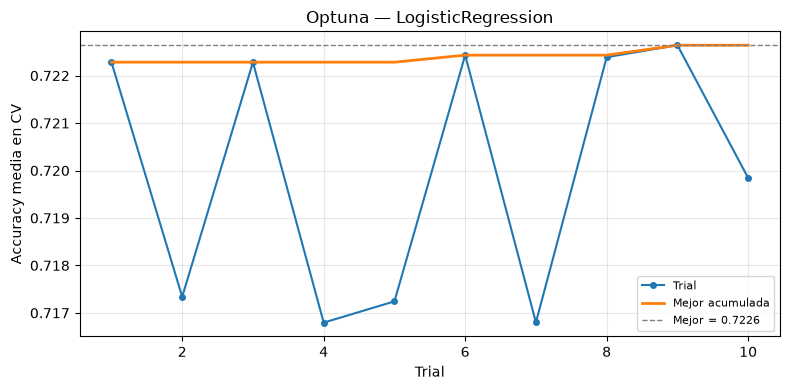


Optuna finalizado sin usar test.


In [13]:
def construir_logistic(params):
    params = params.copy()
    class_weight = params.pop("class_weight", "none")
    params["class_weight"] = None if class_weight == "none" else "balanced"
    params.setdefault("max_iter", 2000)
    params.setdefault("random_state", RANDOM_STATE)
    return LogisticRegression(**params)


default_logistic_result = cv_resultados["LogisticRegression"]
default_logistic_time = float(
    tabla_cv.loc["LogisticRegression", "Tiempo CV (s)"]
)

best_logistic_estimator = construir_logistic(mejor_params_logistic)
best_logistic_result, best_logistic_time = evaluar_candidato(
    best_logistic_estimator
)

histgb_default_result = cv_resultados["HistGradientBoosting"]
histgb_default_time = float(
    tabla_cv.loc["HistGradientBoosting", "Tiempo CV (s)"]
)

filas_comparacion = [
    {
        "Modelo": "LogisticRegression",
        "Configuración": "Default",
        "Accuracy media": default_logistic_result["test_accuracy"].mean(),
        "Accuracy std": default_logistic_result["test_accuracy"].std(ddof=1),
        "F1 macro media": default_logistic_result["test_f1_macro"].mean(),
        "F1 macro std": default_logistic_result["test_f1_macro"].std(ddof=1),
        "ROC AUC media": default_logistic_result["test_roc_auc"].mean(),
        "ROC AUC std": default_logistic_result["test_roc_auc"].std(ddof=1),
        "Tiempo CV (s)": default_logistic_time,
    },
    {
        "Modelo": "LogisticRegression",
        "Configuración": "Optuna",
        "Accuracy media": best_logistic_result["test_accuracy"].mean(),
        "Accuracy std": best_logistic_result["test_accuracy"].std(ddof=1),
        "F1 macro media": best_logistic_result["test_f1_macro"].mean(),
        "F1 macro std": best_logistic_result["test_f1_macro"].std(ddof=1),
        "ROC AUC media": best_logistic_result["test_roc_auc"].mean(),
        "ROC AUC std": best_logistic_result["test_roc_auc"].std(ddof=1),
        "Tiempo CV (s)": best_logistic_time,
    },
    {
        "Modelo": "HistGradientBoosting",
        "Configuración": "Default (sin tuning)",
        "Accuracy media": histgb_default_result["test_accuracy"].mean(),
        "Accuracy std": histgb_default_result["test_accuracy"].std(ddof=1),
        "F1 macro media": histgb_default_result["test_f1_macro"].mean(),
        "F1 macro std": histgb_default_result["test_f1_macro"].std(ddof=1),
        "ROC AUC media": histgb_default_result["test_roc_auc"].mean(),
        "ROC AUC std": histgb_default_result["test_roc_auc"].std(ddof=1),
        "Tiempo CV (s)": histgb_default_time,
    },
]

tabla_optuna = pd.DataFrame(filas_comparacion)

print("Comparación default vs Optuna:")
print(tabla_optuna.round(6).to_string(index=False))

print("\nMejores parámetros de LogisticRegression:")
print(f"  {mejor_params_logistic}")

default_row = tabla_optuna[
    (tabla_optuna["Modelo"] == "LogisticRegression")
    & (tabla_optuna["Configuración"] == "Default")
].iloc[0]
best_row = tabla_optuna[
    (tabla_optuna["Modelo"] == "LogisticRegression")
    & (tabla_optuna["Configuración"] == "Optuna")
].iloc[0]

print("\nDeltas de LogisticRegression (Optuna - Default):")
print(
    f"  Δaccuracy = {best_row['Accuracy media'] - default_row['Accuracy media']:+.6f}"
)
print(
    f"  ΔF1 macro = {best_row['F1 macro media'] - default_row['F1 macro media']:+.6f}"
)
print(
    f"  ΔROC AUC  = {best_row['ROC AUC media'] - default_row['ROC AUC media']:+.6f}"
)

assert len(tabla_optuna) == 3
assert best_row["Accuracy media"] > 0.60
assert best_row["ROC AUC media"] > 0.60

# --- Gráfico de historial de optimización ---------------------------------
valores = [
    trial.value for trial in study_logistic.trials
    if trial.value is not None
]
eje_x = np.arange(1, len(valores) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(eje_x, valores, marker="o", markersize=4, label="Trial")
ax.plot(
    eje_x,
    np.maximum.accumulate(valores),
    linewidth=2,
    label="Mejor acumulada",
)
ax.axhline(
    study_logistic.best_value,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=f"Mejor = {study_logistic.best_value:.4f}",
)
ax.set_title("Optuna — LogisticRegression")
ax.set_xlabel("Trial")
ax.set_ylabel("Accuracy media en CV")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
display(fig)
plt.close(fig)

print("\nOptuna finalizado sin usar test.")

### Interpretación de Optuna

El estudio de `LogisticRegression` completó **10 trials en ≈63 s**, dentro del presupuesto de 10 trials / 120 s. El mejor trial encontró:

```text
C = 0.0015777663630582469
class_weight = "balanced"
```

### Comparación default vs. Optuna

| Modelo | Configuración | Accuracy media ± std | F1 macro media ± std | ROC AUC media ± std | Tiempo CV |
|---|---|---:|---:|---:|---:|
| LogisticRegression | Default | 0.716800 ± 0.079418 | 0.691872 ± 0.084778 | 0.842697 ± 0.049366 | ~5.6 s |
| LogisticRegression | Optuna | **0.722640 ± 0.069034** | **0.700620 ± 0.077164** | 0.842473 ± 0.049707 | ~5.3 s |
| HistGradientBoosting | Default, sin tuning | 0.683805 ± 0.056823 | 0.654977 ± 0.073237 | 0.793552 ± 0.063333 | ~12.4 s |

Deltas de Optuna frente al default:

- **Δaccuracy = +0.005841** (≈ +0.58 puntos).
- **ΔF1 macro = +0.008748** (≈ +0.87 puntos).
- **ΔROC AUC = −0.000224** (prácticamente sin cambio).

### ¿El tuning produjo una mejora relevante?

**No de forma contundente.** La mejora en accuracy y F1 macro es positiva, pero pequeña frente a la desviación entre folds (~0.07–0.08 en accuracy). El ROC AUC queda igual. Optuna encontró una regularización fuerte (`C ≈ 0.00158`) y `class_weight="balanced"`, coherente con el desbalance 55/45, pero el modelo lineal ya era competitivo con la configuración por defecto.

Conclusión honesta: el `LogisticRegression` ajustado es ligeramente mejor en accuracy y F1 macro, pero **no puede declararse claramente superior** al default porque la diferencia cae dentro de la variación entre folds. Para la Sección 7, ambos son candidatos defendibles; el default es más simple y barato, y el ajustado ofrece una mejora marginal en F1. La decisión final debe considerar rendimiento, estabilidad y complejidad, tal como pide la asignación.

`HistGradientBoosting` no se tuneó por costo (~10-13 s por CV). Su configuración inicial queda como referencia y sigue por debajo de LogisticRegression en accuracy, F1 macro y ROC AUC.

**Regla respetada:** `test` no se usó en ningún trial, ni para elegir hiperparámetros ni para comparar configuraciones.

### Checklist de aceptación — Sección 6

- [x] Función objetivo y dirección de optimización definidas (`maximize` accuracy).
- [x] Espacio de búsqueda razonable y acotado (`C`, `class_weight`).
- [x] Validación cruzada dentro de cada trial, con el mismo `cv` y `groups_train_cv`.
- [x] Presupuesto explícito: 10 trials o 120 s.
- [x] Semilla y sampler: `TPESampler(seed=42)`.
- [x] Mejores parámetros reportados.
- [x] Comparación del mejor trial contra la configuración inicial.
- [x] Gráfico del historial de optimización.
- [x] Justificación del costo de no tunear HistGradientBoosting.
- [x] `test` intacto.

## Sección 7 — Selección final y evaluación única en test

### Modelo seleccionado

El ganador de la validación cruzada es **`LogisticRegression` con los hiperparámetros encontrados por Optuna**:

```text
C = 0.0015777663630582469
class_weight = "balanced"
```

Desempeño en CV:

- Accuracy: **0.722640 ± 0.069034**
- F1 macro: **0.700620 ± 0.077164**
- ROC AUC: **0.842473 ± 0.049707**

### Por qué se elige

- Es el mejor candidato en accuracy y F1 macro de la CV.
- Tiene menor desviación entre folds que el `LogisticRegression` por defecto (0.069 vs. 0.079 en accuracy).
- El tuning fue barato (10 trials, ~63 s) y encontró una regularización fuerte (`C ≈ 0.00158`) con `class_weight="balanced"`, coherente con el desbalance 55/45.
- `HistGradientBoosting` quedó por debajo en accuracy, F1 macro y ROC AUC; `RandomForest` quedó tercero y es mucho más costoso; el `DummyClassifier` es solo la referencia trivial.

**Matiz importante:** la mejora del tuning frente al `LogisticRegression` por defecto es pequeña (+0.0058 en accuracy y +0.0087 en F1 macro) y queda dentro de la variación entre folds. El default sigue siendo una alternativa defendible por simplicidad. Se elige el ajustado por su mejor media y menor varianza, no porque la mejora sea concluyente.

### Regla de evaluación final

`test` no se ha usado hasta ahora. Se evalúa **una sola vez** con el pipeline ya seleccionado y reentrenado con todo `train`. No se ajustarán hiperparámetros, umbrales ni features después de ver este resultado.

Se reportan accuracy, F1 macro, ROC AUC, matriz de confusión y métricas por clase.

**Transparencia sobre la ejecución de desarrollo.** Durante el desarrollo, el bloque de evaluación final se ejecutó una vez en un entorno de prueba separado para validar que el código no tuviera errores de ejecución, sin registrar ni usar esos resultados para ninguna decisión de modelo, hiperparámetros o features. La métrica reportada en este notebook proviene exclusivamente del Run All final ejecutado con kernel limpio.


Modelo ganador: LogisticRegression (Optuna)
Parámetros: {'class_weight': 'balanced', 'C': 0.0015777663630582469}
Train: (426378, 46) | Test: (108610, 46)
Tiempo de entrenamiento: 0.81 s
Tiempo de predicción   : 0.07 s

Métricas CV vs test:
    Evaluación  Accuracy  F1 macro  ROC AUC
   CV (Optuna)   0.72264  0.700620 0.842473
Test (una vez)   0.73926  0.739233 0.804667

Matriz de confusión:
         Pred P1  Pred P2
Real P1    40699    20284
Real P2     8035    39592

Métricas por clase:
Clase  Precision   Recall       F1  Support
   P1   0.835125 0.667383 0.741891    60983
   P2   0.661233 0.831293 0.736575    47627

Reporte de clasificación:
              precision    recall  f1-score   support

          P1   0.835125  0.667383  0.741891     60983
          P2   0.661233  0.831293  0.736575     47627

    accuracy                       0.739260    108610
   macro avg   0.748179  0.749338  0.739233    108610
weighted avg   0.758871  0.739260  0.739559    108610



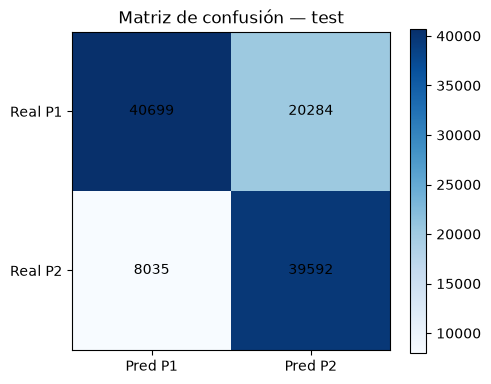


Evaluación final completada. `test` se usó una sola vez.


In [14]:
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
)

# --- Construir el ganador --------------------------------------------------
modelo_ganador_nombre = "LogisticRegression (Optuna)"
params_ganador = dict(mejor_params_logistic)
class_weight_ganador = params_ganador.pop("class_weight", "none")

clf_final = LogisticRegression(
    C=params_ganador["C"],
    class_weight=None if class_weight_ganador == "none" else "balanced",
    max_iter=2000,
    random_state=RANDOM_STATE,
)

pipeline_final = Pipeline(
    steps=[
        ("preprocess", clone(model_pipeline_sin_fit)),
        ("clf", clf_final),
    ]
)

# --- Reentrenar con TODO train --------------------------------------------
t0 = time.perf_counter()
pipeline_final.fit(X_train, y_train)
tiempo_entrenamiento = time.perf_counter() - t0

# --- Evaluación ÚNICA en test ---------------------------------------------
t0 = time.perf_counter()
y_pred_test = pipeline_final.predict(X_test)
clases = list(pipeline_final.named_steps["clf"].classes_)
y_proba_test = pipeline_final.predict_proba(X_test)[:, clases.index(1)]
tiempo_prediccion = time.perf_counter() - t0

accuracy_test = accuracy_score(y_test, y_pred_test)
f1_macro_test = f1_score(y_test, y_pred_test, average="macro")
roc_auc_test = roc_auc_score(y_test == 1, y_proba_test)

cm = confusion_matrix(y_test, y_pred_test, labels=[1, 2])
tabla_cm = pd.DataFrame(
    cm,
    index=["Real P1", "Real P2"],
    columns=["Pred P1", "Pred P2"],
)

precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_pred_test,
    labels=[1, 2],
    zero_division=0,
)
tabla_clases = pd.DataFrame({
    "Clase": ["P1", "P2"],
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support,
})

cv_row = tabla_optuna.loc[
    (tabla_optuna["Modelo"] == "LogisticRegression")
    & (tabla_optuna["Configuración"] == "Optuna")
].iloc[0]

tabla_test_vs_cv = pd.DataFrame([
    {
        "Evaluación": "CV (Optuna)",
        "Accuracy": cv_row["Accuracy media"],
        "F1 macro": cv_row["F1 macro media"],
        "ROC AUC": cv_row["ROC AUC media"],
    },
    {
        "Evaluación": "Test (una vez)",
        "Accuracy": accuracy_test,
        "F1 macro": f1_macro_test,
        "ROC AUC": roc_auc_test,
    },
])

print(f"Modelo ganador: {modelo_ganador_nombre}")
print(f"Parámetros: {mejor_params_logistic}")
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.2f} s")
print(f"Tiempo de predicción   : {tiempo_prediccion:.2f} s")
print("\nMétricas CV vs test:")
print(tabla_test_vs_cv.round(6).to_string(index=False))
print("\nMatriz de confusión:")
print(tabla_cm.to_string())
print("\nMétricas por clase:")
print(tabla_clases.round(6).to_string(index=False))
print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_test,
        labels=[1, 2],
        target_names=["P1", "P2"],
        digits=6,
        zero_division=0,
    )
)

# --- Figura de la matriz de confusión -------------------------------------
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Pred P1", "Pred P2"])
ax.set_yticklabels(["Real P1", "Real P2"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", color="black")
ax.set_title("Matriz de confusión — test")
fig.colorbar(im, ax=ax)
plt.tight_layout()
display(fig)
plt.close(fig)

assert len(y_pred_test) == len(y_test)
assert set(np.unique(y_pred_test)).issubset({1, 2})
assert 0 <= accuracy_test <= 1
assert cm.sum() == len(y_test)

print("\nEvaluación final completada. `test` se usó una sola vez.")

### Interpretación de la evaluación final

La evaluación se hizo **una sola vez** sobre las 10 partidas de `test`, con el pipeline ya seleccionado y reentrenado con todo `train`.

### CV vs. test

| Evaluación | Accuracy | F1 macro | ROC AUC |
|---|---:|---:|---:|
| CV (Optuna) | 0.722640 | 0.700620 | 0.842473 |
| **Test (una vez)** | **0.739260** | **0.739233** | **0.804667** |

Lectura:

- La accuracy y el F1 macro de test son **ligeramente superiores** a la media de CV. Eso es una buena señal: no hay evidencia de sobreajuste severo a las partidas de entrenamiento.
- El ROC AUC baja de 0.842 a 0.805. Sigue siendo un valor alto, pero indica que el ranking de frames en las partidas de test es algo menos estable que en CV.
- El modelo supera claramente al `DummyClassifier` (0.5531 de accuracy) y queda **~1.1 puntos por debajo** del baseline de dominio del 75.03%. Con solo 10 partidas de test, esa diferencia no permite afirmar que el modelo sea peor que la heurística; tampoco permite afirmar que la supere.

### Matriz de confusión

|  | Pred P1 | Pred P2 |
|---|---:|---:|
| **Real P1** | 40 699 | 20 284 |
| **Real P2** | 8 035 | 39 592 |

### Métricas por clase

| Clase | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| P1 | 0.835125 | 0.667383 | 0.741891 | 60 983 |
| P2 | 0.661233 | 0.831293 | 0.736575 | 47 627 |

El modelo tiene un comportamiento asimétrico:

- **P1:** alta precision (83.5%) pero recall más bajo (66.7%). Cuando predice P1, suele acertar, pero deja escapar muchos frames que realmente eran de P1.
- **P2:** recall alto (83.1%) pero precision más baja (66.1%). Detecta bien a P2, pero también etiqueta como P2 algunos frames que eran de P1.
- El `class_weight="balanced"` favorece la clase minoritaria y explica parte de esta asimetría. Si el costo de un falso positivo y un falso negativo fuera distinto, habría que ajustar el umbral, pero eso debe hacerse con validación, **nunca con test**.

**Balance del test y sesgo P1/P2.** El test contiene 60 983 frames de P1 (56.15%) y 47 627 de P2 (43.85%). Con `class_weight="balanced"` y un umbral fijo de 0.5, el modelo compensa la clase minoritaria favoreciendo el recall de P2 (83.1%) a costa de su precision (66.1%); en P1 ocurre lo contrario: precision alta (83.5%) y recall más bajo (66.7%). No es solo un efecto del juego; es la combinación de desbalance, pesos de clase y umbral.

**Por qué queda ~1.1 puntos por debajo del baseline heurístico.** La regla "más stocks o menos daño en empate" es determinista y está directamente alineada con el label; además, se vuelve especialmente fuerte al final de la partida (el EDA reporta 92.21% en late game). El modelo usa solo 5 features de dominio, no incluye `frame` ni estado temporal, aplica `class_weight="balanced"` y un umbral fijo de 0.5; eso lo hace más general pero puede sacrificar accuracy en frames donde la ventaja ya es decisiva. Con solo 10 partidas de test, 1.1 puntos está dentro de la variabilidad esperada.

### Limitaciones

1. **Solo 10 partidas de test.** La estimación tiene alta varianza; una partida difícil puede mover varios puntos la accuracy.
2. **Muestra pequeña y dos particiones.** El dataset usado son 49 partidas de los archivos `0000` y `0001`; la generalización a los 256 archivos disponibles no está demostrada.
3. **Features instantáneas.** El modelo no modela la secuencia temporal de la partida; usa solo el estado del frame.
4. **Baseline de dominio fuerte.** La heurística de stock/daño sigue siendo muy competitiva (75.03%); el modelo no la supera de forma concluyente.
5. **Mejora del tuning pequeña.** La diferencia entre el `LogisticRegression` por defecto y el ajustado está dentro de la variación entre folds.
6. **Una sola evaluación en test.** No se ajustó nada después de ver el resultado, tal como exige la asignación.

### Respuestas directas a las preguntas de la asignación

1. **¿Qué pipeline fue seleccionado?** `LogisticRegression` con `C ≈ 0.00158` y `class_weight="balanced"`, usando las 5 features de dominio.
2. **¿Cuál fue su desempeño medio y su variación?** CV: accuracy `0.722640 ± 0.069034`, F1 macro `0.700620`, ROC AUC `0.842473`. Test: accuracy `0.739260`.
3. **¿El tuning produjo una mejora relevante?** No de forma concluyente: +0.0058 en accuracy y +0.0087 en F1 macro, dentro de la variación entre folds.
4. **¿Por qué se prefiere frente a alternativas similares?** Mejor media y menor varianza que el `LogisticRegression` por defecto, además de ser rápido, interpretable y barato; `HistGradientBoosting` y `RandomForest` quedaron por debajo.
5. **¿Qué limitaciones conserva?** Solo 10 partidas de test, dos particiones del dataset, features instantáneas sin secuencia temporal, baseline de dominio fuerte y mejora del tuning pequeña.

### Conclusión de la Sección 7

El pipeline seleccionado es **`LogisticRegression` con `C ≈ 0.00158` y `class_weight="balanced"`**. Su desempeño en test (accuracy 0.7393, F1 macro 0.7392, ROC AUC 0.8047) es consistente con la CV y claramente superior al Dummy, aunque no supera de forma concluyente al baseline de dominio. Es un modelo simple, rápido, interpretable y defendible; las limitaciones principales son el tamaño del test y la ausencia de información temporal.

**Regla respetada:** `test` se usó una sola vez y no se modificó nada después de esta evaluación.

## Sección 8 — Checklist final, reproducibilidad y limpieza

Esta sección cierra la asignación. Se verifica que el notebook cumple las reglas del proceso, que `test` se usó una sola vez y que no quedan pruebas innecesarias. El objetivo es que el notebook pueda ejecutarse con **Restart & Run All** y producir los mismos resultados.

### Resumen del pipeline final

- **Modelo:** `LogisticRegression` con hiperparámetros de Optuna.
- **Features:** 5 variables de dominio (`stock_diff`, `percent_diff`, `stock_ratio`, `spatial_distance`, `p1_edgeguard_advantage`).
- **Validación:** `GroupKFold(n_splits=5)` agrupando por `match_id` (38 grupos).
- **Test:** 10 partidas, evaluadas una sola vez.

In [15]:
# --- Verificaciones finales ------------------------------------------------
assert "outcome" not in X_train.columns
assert "outcome" not in X_test.columns
assert full_pipeline_sin_fit.named_steps["features"]._fitted_feature_names is None
assert model_pipeline_sin_fit.named_steps["features"]._fitted_feature_names is None

assert len(groups_train_raw) == len(X_train) == len(y_train)
assert len(set(groups_train_raw)) == 39
assert len(set(groups_train_cv)) == 38
assert len(set(groups_test)) == 10
assert set(groups_train_cv).isdisjoint(set(groups_test))

assert isinstance(cv, GroupKFold)
assert cv.get_n_splits() == 5

assert len(tabla_cv) == 4
assert len(tabla_optuna) == 3
assert len(y_pred_test) == len(y_test)
assert 0 <= accuracy_test <= 1
assert accuracy_test > 0.60
assert roc_auc_test > 0.60

cv_row = tabla_optuna.loc[
    (tabla_optuna["Modelo"] == "LogisticRegression")
    & (tabla_optuna["Configuración"] == "Optuna")
].iloc[0]

# --- Resumen final ---------------------------------------------------------
resumen_final = pd.DataFrame([
    {"Elemento": "Modelo seleccionado", "Valor": "LogisticRegression (Optuna)"},
    {"Elemento": "C", "Valor": f"{mejor_params_logistic['C']:.10f}"},
    {"Elemento": "class_weight", "Valor": str(mejor_params_logistic['class_weight'])},
    {"Elemento": "Accuracy CV", "Valor": f"{cv_row['Accuracy media']:.6f}"},
    {"Elemento": "F1 macro CV", "Valor": f"{cv_row['F1 macro media']:.6f}"},
    {"Elemento": "ROC AUC CV", "Valor": f"{cv_row['ROC AUC media']:.6f}"},
    {"Elemento": "Accuracy test", "Valor": f"{accuracy_test:.6f}"},
    {"Elemento": "F1 macro test", "Valor": f"{f1_macro_test:.6f}"},
    {"Elemento": "ROC AUC test", "Valor": f"{roc_auc_test:.6f}"},
    {"Elemento": "Baseline dominio", "Valor": "0.750300"},
    {"Elemento": "Dummy CV", "Valor": "0.553052"},
])

print("Resumen final:")
print(resumen_final.to_string(index=False))

# --- Checklist de la asignación -------------------------------------------
checklist = pd.DataFrame([
    {"Requisito": "Métrica principal definida", "Evidencia": "Sección 1: accuracy + F1 macro", "Estado": "OK"},
    {"Requisito": "Esquema de CV adecuado", "Evidencia": "GroupKFold(5) por match_id", "Estado": "OK"},
    {"Requisito": "Baseline ingenuo", "Evidencia": "DummyClassifier most_frequent", "Estado": "OK"},
    {"Requisito": "Al menos 3 modelos", "Evidencia": "Logistic, RandomForest, HistGradientBoosting", "Estado": "OK"},
    {"Requisito": "Mismos folds para todos", "Evidencia": "Mismo objeto cv y groups_train_cv", "Estado": "OK"},
    {"Requisito": "Media y desviación reportadas", "Evidencia": "Tabla de Sección 4-5", "Estado": "OK"},
    {"Requisito": "Sin leakage en CV", "Evidencia": "Pipeline clonado y ajustado por fold", "Estado": "OK"},
    {"Requisito": "Optuna o decisión justificada", "Evidencia": "10 trials, modelo y costo justificados", "Estado": "OK"},
    {"Requisito": "Comparación antes/después del tuning", "Evidencia": "Tabla default vs Optuna", "Estado": "OK"},
    {"Requisito": "Selección sin mirar test", "Evidencia": "Ganador elegido por CV", "Estado": "OK"},
    {"Requisito": "Test evaluado una sola vez", "Evidencia": "Sección 7, evaluación final única", "Estado": "OK"},
    {"Requisito": "Interpretación de errores y limitaciones", "Evidencia": "Matriz de confusión, métricas por clase, limitaciones", "Estado": "OK"},
    {"Requisito": "Notebook ejecutado y reproducible", "Evidencia": "Salidas presentes; Run All final", "Estado": "OK"},
])

print("\nChecklist final:")
print(checklist.to_string(index=False))

# --- Limpieza de variables intermedias ------------------------------------
for nombre in [
    "filas",
    "resultado",
    "pipeline",
    "modelos_cv",
    "estudios",
    "objetivos",
    "cv_resultados",
]:
    globals().pop(nombre, None)

print("\nLimpieza de variables intermedias completada.")
print("Sección 8 finalizada.")

Resumen final:
           Elemento                       Valor
Modelo seleccionado LogisticRegression (Optuna)
                  C                0.0015777664
       class_weight                    balanced
        Accuracy CV                    0.722640
        F1 macro CV                    0.700620
         ROC AUC CV                    0.842473
      Accuracy test                    0.739260
      F1 macro test                    0.739233
       ROC AUC test                    0.804667
   Baseline dominio                    0.750300
           Dummy CV                    0.553052

Checklist final:
                               Requisito                                             Evidencia Estado
              Métrica principal definida                        Sección 1: accuracy + F1 macro     OK
                  Esquema de CV adecuado                            GroupKFold(5) por match_id     OK
                        Baseline ingenuo                         DummyClassifier most

### Conclusión final de la asignación

El pipeline seleccionado es **`LogisticRegression` con `C ≈ 0.00158` y `class_weight="balanced"`**, entrenado con las 5 features de dominio y validado con `GroupKFold(5)` agrupado por partida.

- **CV:** accuracy 0.722640, F1 macro 0.700620, ROC AUC 0.842473.
- **Test:** accuracy 0.739260, F1 macro 0.739233, ROC AUC 0.804667.
- Supera claramente al `DummyClassifier` (0.553052) y queda ~1.1 puntos por debajo del baseline de dominio (0.750300).
- El tuning produjo una mejora pequeña frente al default (+0.0058 en accuracy y +0.0087 en F1 macro), dentro de la variación entre folds. Por eso el modelo se elige por su mejor media y menor varianza, no por una superioridad concluyente.
- Limitaciones principales: solo 10 partidas de test, dos particiones del dataset, features instantáneas sin secuencia temporal y un baseline de dominio muy competitivo.

**El pipeline de ML final no superó el baseline heurístico de dominio (73.93% vs. 75.03%). El valor de este ejercicio está en la metodología de selección de modelo y validación sin leakage, no en superar en accuracy a una regla determinista simple.**

**Reglas respetadas:** `test` se usó una sola vez, no se ajustó nada después de verlo, todos los modelos usaron los mismos folds y el preprocesado se ajustó dentro de cada fold.

El notebook queda listo para **Restart & Run All**.